# TP — Apprentissage auto-supervisé
Kaggle : activer **GPU** et **Internet**, puis exécuter les cellules dans l’ordre. Le compte rendu est rédigé séparément.

## Consignes 1–2 — Démonstrations originales

In [1]:
# Installer la bibliothèque et ses correctifs de compatibilité.
from pathlib import Path
import os, sys, subprocess, importlib.util, urllib.request, zipfile
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Activer GPU dans les paramètres Kaggle, puis relancer cette cellule.')
base = Path('/kaggle/temp/tp_ssl')
base.mkdir(parents=True, exist_ok=True)
ORIGINAL_LIBRARY = base / 'cs294-158-ssl'
revision = 'f75521d44e91427e528a3d507fdd76d376445f1a'
if not ORIGINAL_LIBRARY.exists():
    subprocess.run(['git', 'clone', 'https://github.com/ckurtz/cs294-158-ssl', str(ORIGINAL_LIBRARY)], check=True)
current = subprocess.check_output(['git', '-C', str(ORIGINAL_LIBRARY), 'rev-parse', 'HEAD'], text=True).strip()
if current != revision:
    subprocess.run(['git', '-C', str(ORIGINAL_LIBRARY), 'checkout', revision], check=True)
required = {'cv2': 'opencv-python-headless', 'requests': 'requests',
            'pandas': 'pandas', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

fixes = {
 'deepul_helper/tasks/rotation.py': [('targets.to(images.get_device())', 'targets.to(images.device)')],
 'deepul_helper/tasks/simclr.py': [('targets.to(sim_matrix.get_device())', 'targets.to(sim_matrix.device)')],
 'deepul_helper/resnet.py': [('torch.mean(x, dim=[2, 3]).squeeze()', 'torch.mean(x, dim=[2, 3])')],
 'deepul_helper/demos.py': [("map_location='cpu')", "map_location='cpu', weights_only=False)"), ('num_workers=4', 'num_workers=2')],
}
for name, pairs in fixes.items():
    file = ORIGINAL_LIBRARY / name
    content = file.read_text(encoding='utf-8')
    for before, after in pairs:
        content = content.replace(before, after)
    file.write_text(content, encoding='utf-8')
os.chdir(ORIGINAL_LIBRARY)
if str(ORIGINAL_LIBRARY) not in sys.path:
    sys.path.insert(0, str(ORIGINAL_LIBRARY))

def download_teaching_archive(name):

    marker = ORIGINAL_LIBRARY / (name + '.extracted')
    if marker.exists():
        return
    archive = ORIGINAL_LIBRARY / name
    if not archive.exists():
        partial = archive.with_suffix('.partial')
        with urllib.request.urlopen('https://camille-kurtz.com/teaching/' + name, timeout=120) as src, partial.open('wb') as dst:
            while block := src.read(1024*1024):
                dst.write(block)
        partial.replace(archive)
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            if not (ORIGINAL_LIBRARY/member.filename).resolve().is_relative_to(ORIGINAL_LIBRARY.resolve()):
                raise ValueError('Chemin invalide dans une archive.')
        z.extractall(ORIGINAL_LIBRARY)
    marker.write_text('ok')
print('GPU :', torch.cuda.get_device_name(0))


Cloning into '/kaggle/temp/tp_ssl/cs294-158-ssl'...


GPU : Tesla T4


In [2]:
# Télécharger les images des démonstrations.
download_teaching_archive('data.zip')


In [3]:
# Télécharger les poids fournis par l’enseignant.
download_teaching_archive('results.zip')


In [4]:
# Évaluer les modèles fournis et conserver leurs scores.
import torch
from deepul_helper import demos as _original_demos
from deepul_helper.demos import display_nearest_neighbors, show_context_encoder_inpainting
_pretrained_rows = {}

def load_model_and_data(task, dataset='cifar10'):
    model, classifier, train_loader, test_loader = _original_demos.load_model_and_data(task, dataset)

    train_loader.dataset.transform = test_loader.dataset.transform
    model._tp_task = task
    return model, classifier, train_loader, test_loader

@torch.inference_mode()
def evaluate_accuracy(model, linear_classifier, train_loader, test_loader):

    model.eval(); linear_classifier.eval()
    device = next(model.parameters()).device
    row = {'task': model._tp_task, 'source': 'teacher_pretrained'}
    for split, data_loader in [('train', train_loader), ('test', test_loader)]:
        correct1 = correct5 = total = 0
        for images, targets in data_loader:
            if isinstance(images, (list, tuple)):
                images = images[0]
            z = model.encode(images.to(device)).flatten(1)
            predictions = linear_classifier(z).topk(5, dim=1).indices.cpu()
            correct1 += int((predictions[:, 0] == targets).sum())
            correct5 += int((predictions == targets[:, None]).any(1).sum())
            total += len(targets)
        row.update({f'{split}_top1': 100*correct1/total,
                    f'{split}_top5': 100*correct5/total, f'{split}_n': total})
        print(f"{split}: top-1 = {100*correct1/total:.2f}%, top-5 = {100*correct5/total:.2f}%")
    _pretrained_rows[model._tp_task] = row

get_ipython().run_line_magic('matplotlib', 'inline')


### Démo 1 — Context Encoder

In [5]:
# Architecture du Context Encoder.
import torch
import torch.nn as nn
import torch.nn.functional as F

class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        self.encoder = nn.Sequential(

            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4)
        )

        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0),
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1),
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1),
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):

        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()

        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


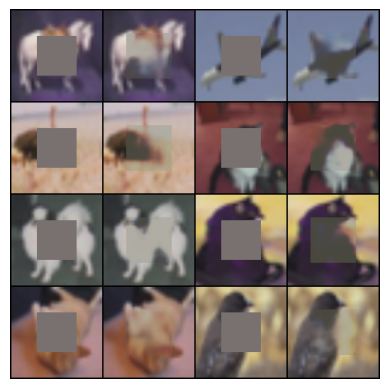

In [6]:
# Reconstructions par inpainting.
show_context_encoder_inpainting()


In [7]:
# Classification sur CIFAR-10.
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)


train: top-1 = 53.24%, top-5 = 94.09%
test: top-1 = 45.77%, top-5 = 90.29%


Image 1


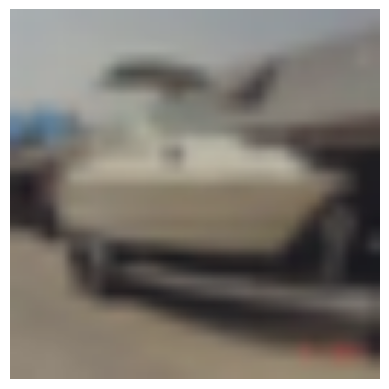

Top 16 Nearest Neighbors (in latent space)


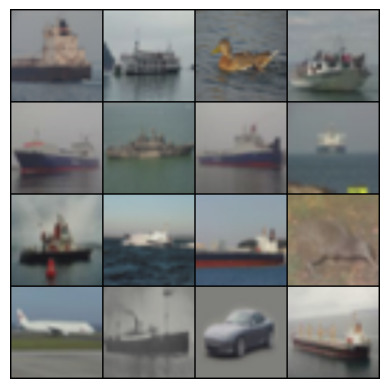

Image 2


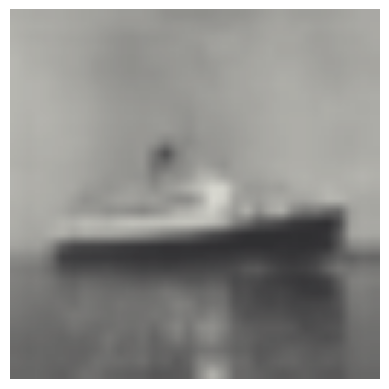

Top 16 Nearest Neighbors (in latent space)


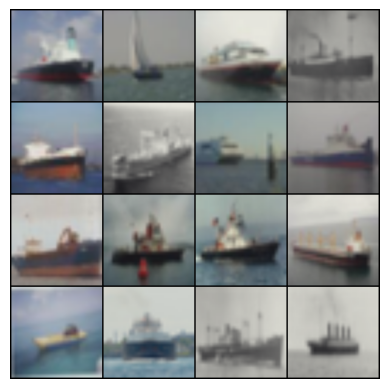

Image 3


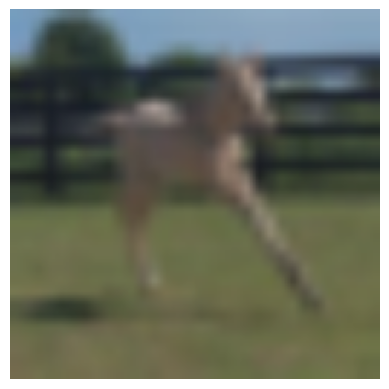

Top 16 Nearest Neighbors (in latent space)


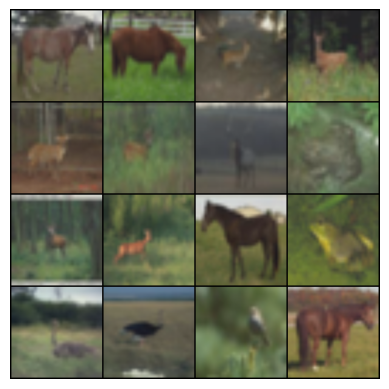

Image 4


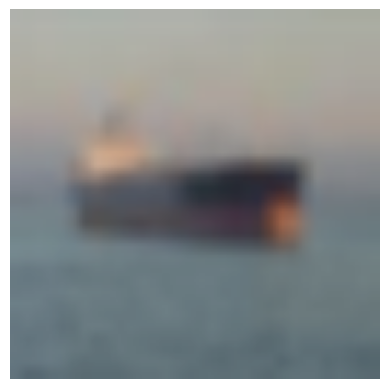

Top 16 Nearest Neighbors (in latent space)


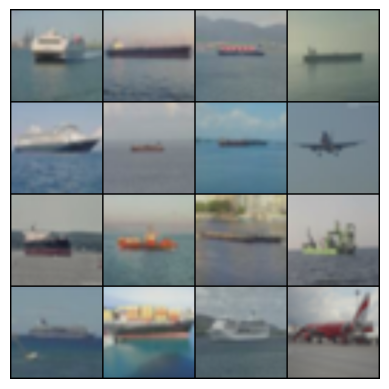

In [8]:
# Plus proches voisins dans les représentations.
display_nearest_neighbors('context_encoder', model, test_loader)


### Démo 2 — Prédiction de rotation

In [9]:
# Architecture de prédiction de rotation.
from deepul_helper.tasks.rotation import NetworkInNetwork, AlexNet
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                nn.Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                nn.Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.device)

        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)

        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets


In [10]:
# Classification sur CIFAR-10.
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)


train: top-1 = 83.54%, top-5 = 99.56%
test: top-1 = 79.91%, top-5 = 99.12%


Image 1


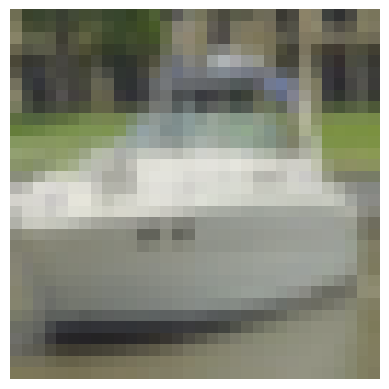

Top 16 Nearest Neighbors (in latent space)


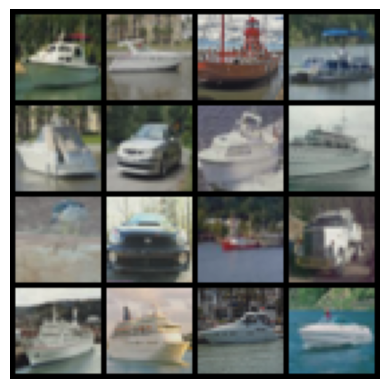

Image 2


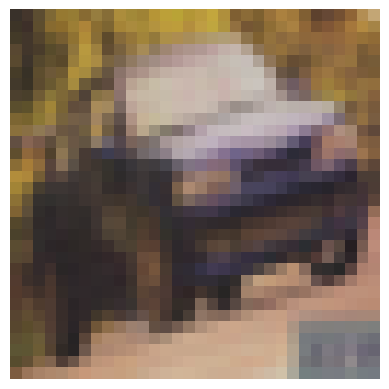

Top 16 Nearest Neighbors (in latent space)


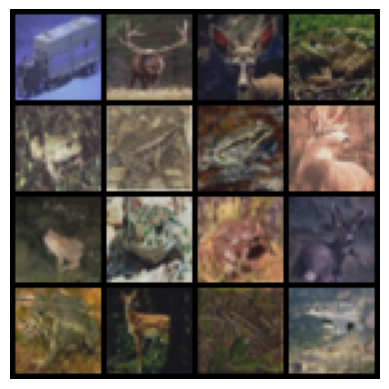

Image 3


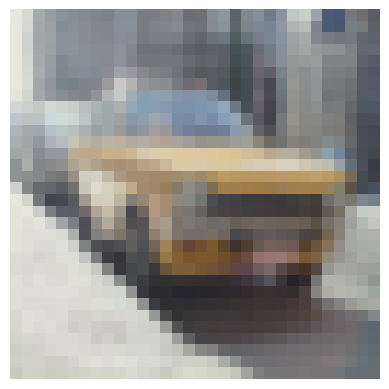

Top 16 Nearest Neighbors (in latent space)


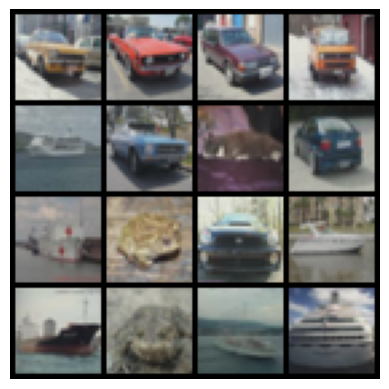

Image 4


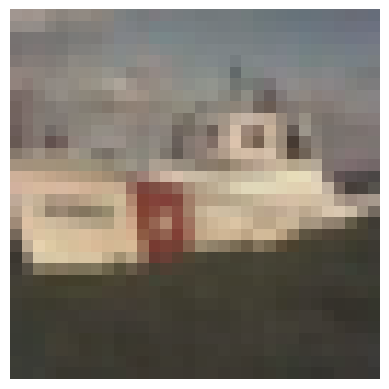

Top 16 Nearest Neighbors (in latent space)


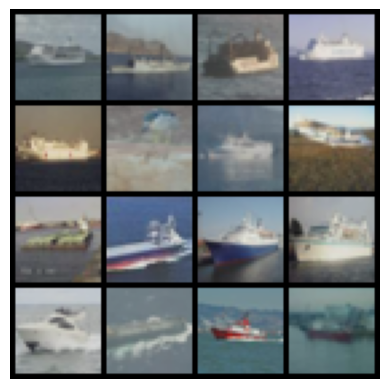

In [11]:
# Plus proches voisins dans les représentations.
display_nearest_neighbors('rotation', model, test_loader)


### Démo 3 — SimCLR

In [12]:
# Architecture SimCLR.
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048

        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj)
        zi, zj = self.proj(hi), self.proj(hj)
        zi, zj = F.normalize(zi), F.normalize(zj)

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0)
        z2 = torch.cat(zis + zjs, dim=0)

        sim_matrix = torch.mm(z1, z2.t())
        sim_matrix = sim_matrix / self.temperature

        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.device).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images)

    def get_features(self, images):
        return self.resnet.get_features(images)


In [13]:
# Classification sur CIFAR-10.
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)


train: top-1 = 93.99%, top-5 = 99.92%
test: top-1 = 92.84%, top-5 = 99.86%


Image 1


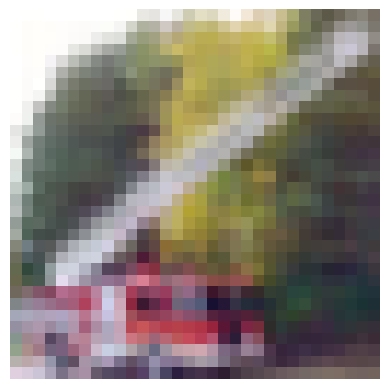

Top 16 Nearest Neighbors (in latent space)


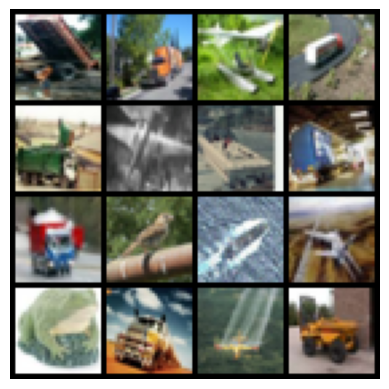

Image 2


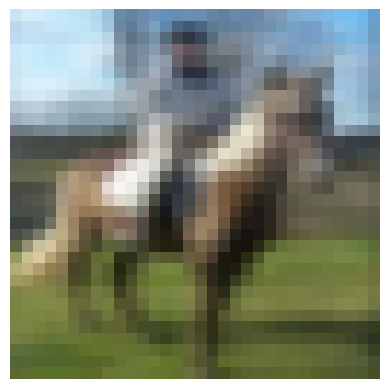

Top 16 Nearest Neighbors (in latent space)


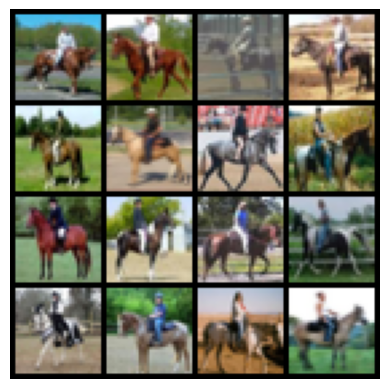

Image 3


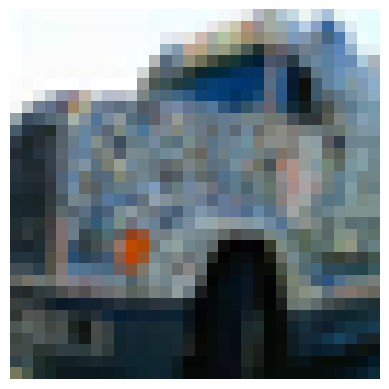

Top 16 Nearest Neighbors (in latent space)


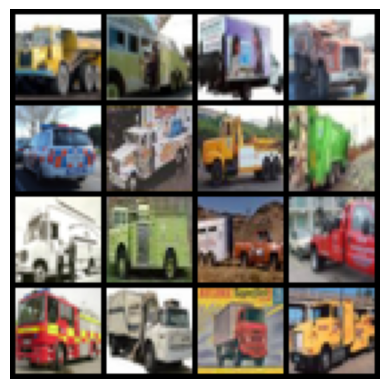

Image 4


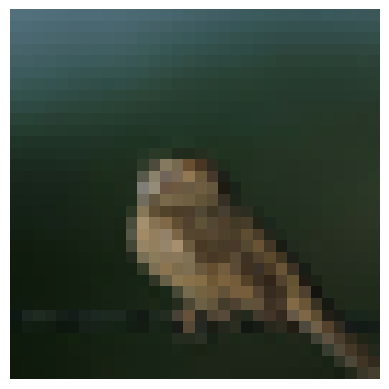

Top 16 Nearest Neighbors (in latent space)


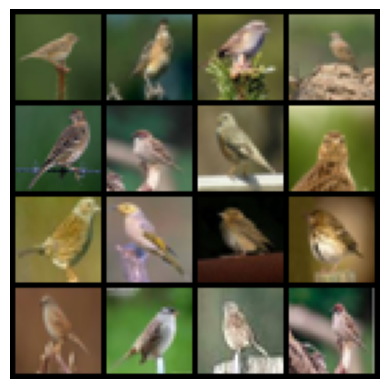

In [14]:
# Plus proches voisins dans les représentations.
display_nearest_neighbors('simclr', model, test_loader)


### Démo 4 — Transfert vers la segmentation

In [15]:
# Architecture de segmentation.
import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.resnet import NormReLU

class SegmentationModel(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, n_classes):
        super().__init__()

        decoder_channels = (512, 256, 128, 64, 32)
        encoder_channels = (2048, 1024, 512, 256, 64)

        in_channels = [encoder_channels[0]] + list(decoder_channels[:-1])
        skip_channels = list(encoder_channels[1:]) + [0]
        out_channels = decoder_channels
        blocks = [
            DecoderBlock(in_ch, skip_ch, out_ch)
            for in_ch, skip_ch, out_ch in zip(in_channels, skip_channels, out_channels)
        ]
        self.dec_blocks = nn.ModuleList(blocks)

        self.seg_head = nn.Conv2d(decoder_channels[-1], n_classes, kernel_size=3, padding=1)

    def forward(self, features, targets):
        features = features[1:]
        features = features[::-1]

        skips = features[1:]
        x = features[0]
        for i, decoder_block in enumerate(self.dec_blocks):
            skip = skips[i] if i < len(skips) else None
            x = decoder_block(x, skip)

        logits = self.seg_head(x)
        loss = F.cross_entropy(logits, targets)

        return dict(Loss=loss), logits

class DecoderBlock(nn.Module):
    def __init__(
            self,
            in_channels,
            skip_channels,
            out_channels,
    ):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels,
                      kernel_size=3, padding=1),
            NormReLU((out_channels, None, None)),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            NormReLU((out_channels, None, None))
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x


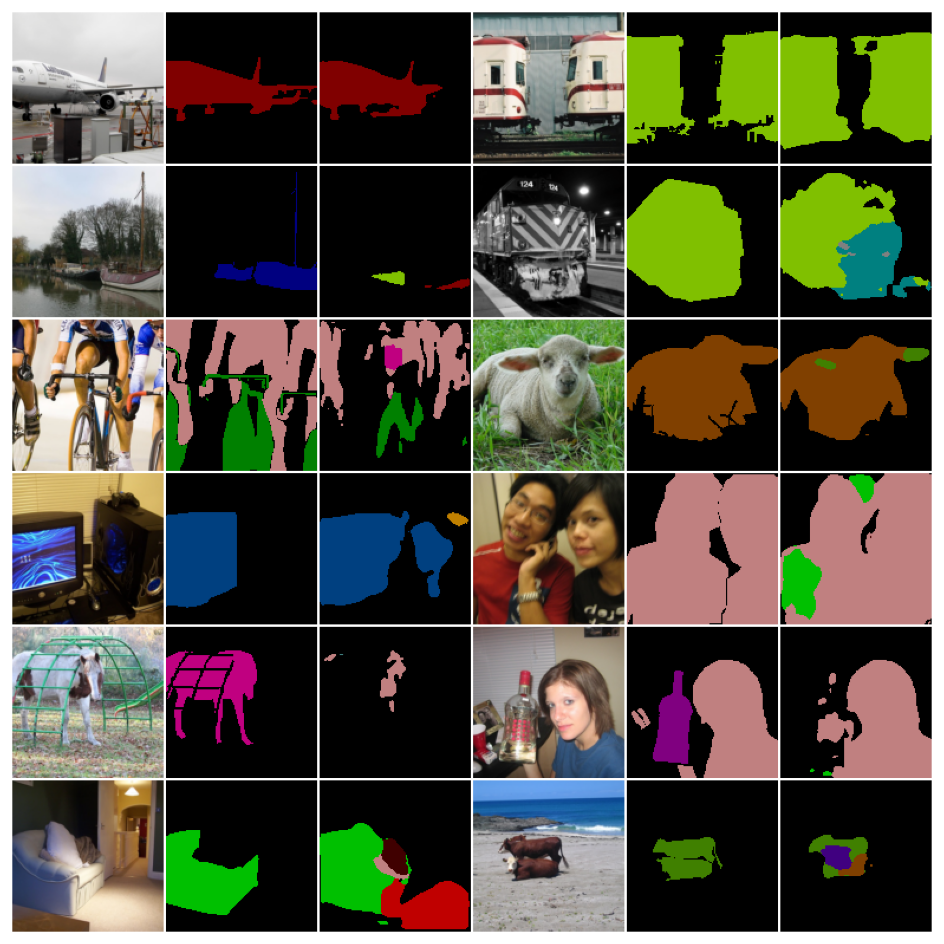

In [16]:
# Exemples de segmentation.
from deepul_helper.demos import show_segmentation
show_segmentation()


### Démo 5 — Raccourcis visuels

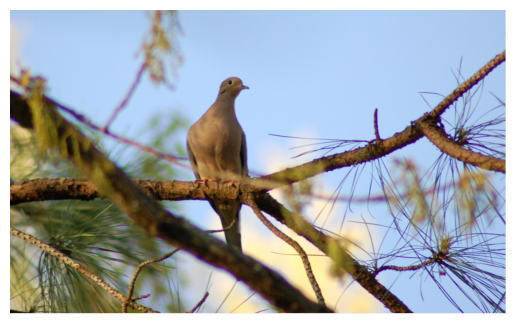

In [17]:
# Exemple d’aberration chromatique.
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/chrom_ab_demo.png')
plt.figure()
plt.axis('off')
plt.imshow(image)
plt.show()


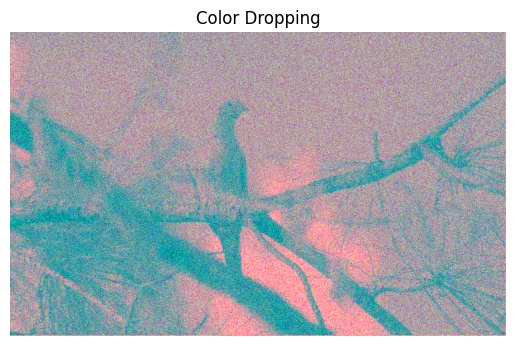

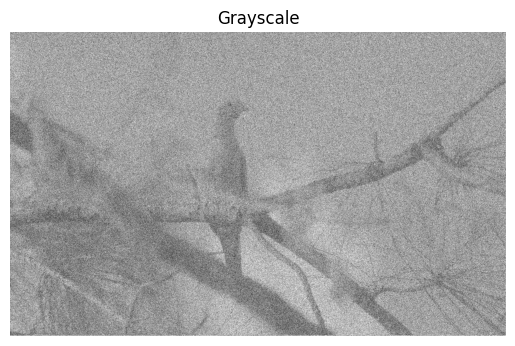

In [18]:
# Réduction des indices de couleur.
import numpy as np

image_cpy = image.convert('RGBA').copy()
pixels = image_cpy.load()

arr = np.array(image_cpy)
std_R = np.std(arr[:, :, 0])
mean_G, mean_B = np.mean(arr[:, :, 1]), np.mean(arr[:, :, 2])

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    R, A = p[0], p[3]
    G = int(np.clip(np.random.randn() * std_R + mean_G, 0, 255))
    B = int(np.clip(np.random.randn() * std_R + mean_B, 0, 255))
    pixels[i, j] = (R, G, B, A)

plt.figure()
plt.title('Color Dropping')
plt.axis('off')
plt.imshow(image_cpy)
plt.show()

image_cpy2 = image.convert('RGBA').copy()
pixels2 = image_cpy2.load()

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    G = int(0.3 * p[0] + 0.59 * p[1] + 0.11 * p[2])
    pixels2[i, j] = (G, G, G, 255)

plt.figure()
plt.title('Grayscale')
plt.axis('off')
plt.imshow(image_cpy2)
plt.show()


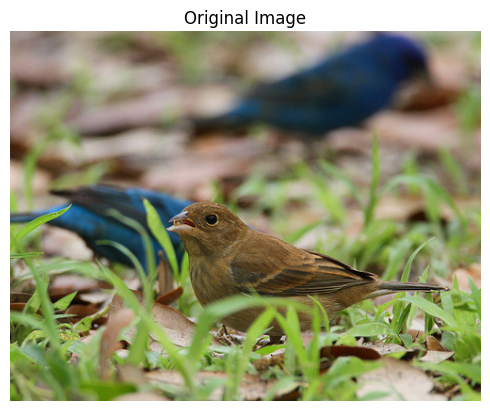

In [19]:
# Image utilisée pour comparer les histogrammes.
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Original Image')
plt.axis('off')
plt.imshow(image)
plt.show()


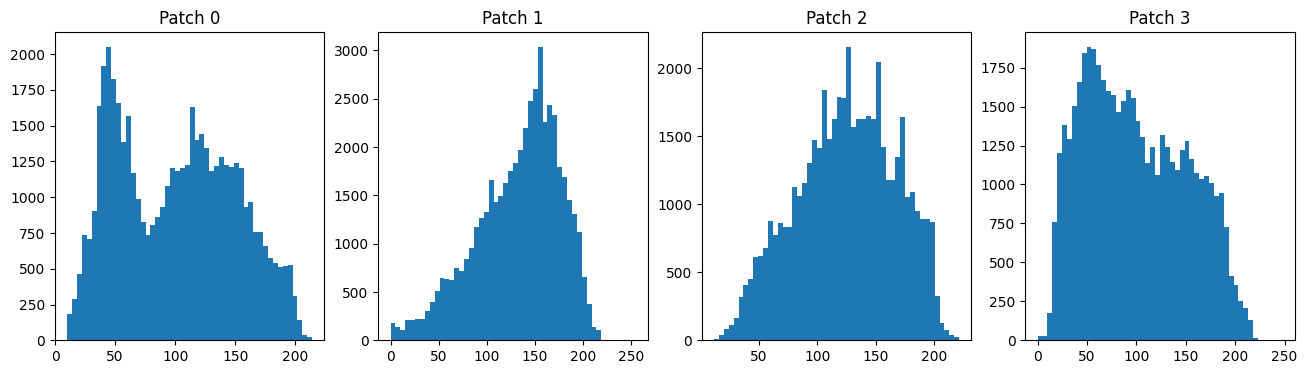

In [20]:
# Histogrammes de quatre patches.
import numpy as np
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()


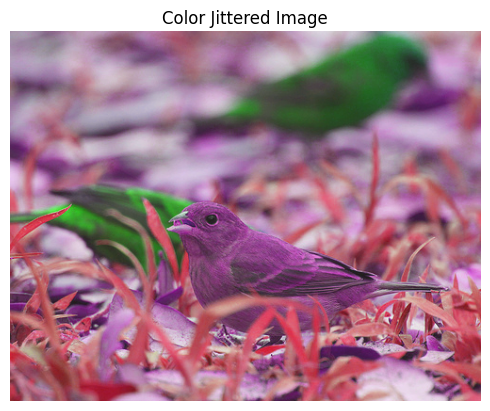

In [21]:
# Augmentation des couleurs (color jitter).
from torchvision import transforms

color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)
jitter_img = color_jitter(image)

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Color Jittered Image')
plt.axis('off')
plt.imshow(jitter_img)
plt.show()


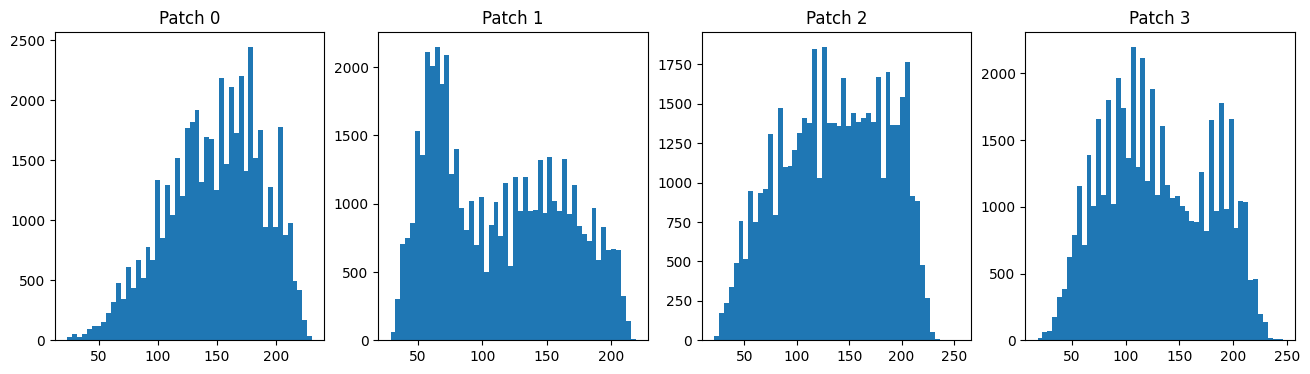

In [23]:
# Histogrammes après augmentation.
arr = np.array(jitter_img)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()


## Consigne 3 — Comparer les modèles fournis sur CIFAR-10

In [24]:
# Tableau des scores mesurés dans les démonstrations.
import pandas as pd
from IPython.display import display
WORK = Path('/kaggle/working/TP_self_supervised')
WORK.mkdir(parents=True, exist_ok=True)
pretrained_results = pd.DataFrame(_pretrained_rows.values())
display(pretrained_results[['task', 'train_top1', 'test_top1', 'test_top5']])
pretrained_results.to_csv(WORK / 'pretrained_comparison.csv', index=False)


,task,train_top1,test_top1,test_top5
0,context_encoder,53.236,45.77,90.29
1,rotation,83.538,79.91,99.12
2,simclr,93.994,92.84,99.86


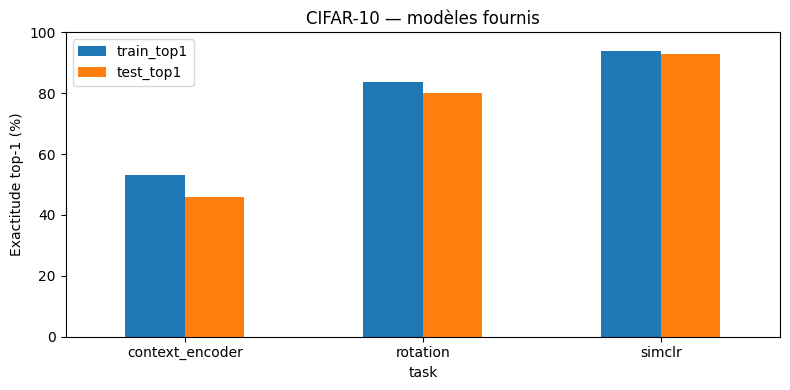

In [25]:
# Comparaison graphique des modèles fournis.
ax = pretrained_results.set_index('task')[['train_top1', 'test_top1']].plot.bar(figsize=(8, 4), rot=0)
ax.set(ylabel='Exactitude top-1 (%)', ylim=(0, 100), title='CIFAR-10 — modèles fournis')
ax.figure.tight_layout()
ax.figure.savefig(WORK / 'pretrained_comparison.png', dpi=160)
plt.show()


## Consignes 4–6 — Entraînement et comparaison
Quatre méthodes sur CIFAR-10 et CIFAR-100 : 45 000 images d’entraînement, 5 000 de validation et 10 000 de test. Préentraînement : 20 époques ; classifieur avec encodeur gelé : 30 époques.

In [27]:
# Paramètres communs et nouveau dossier pour les huit entraînements.
import copy, gc, json, random, shutil, time
from datetime import datetime
import numpy as np
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, transforms as T
from torchvision.transforms import functional as TF

TASKS = ('context_encoder', 'rotation', 'simclr', 'relative_position')
DATASETS = ('cifar10', 'cifar100')
CFG = dict(epochs=20, probe_epochs=30, lr=3e-4, batch_size=128,
           context_batch=32, probe_batch=256, workers=2, seed=0)
RUN_DIR = WORK / ('training_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / 'config.json').write_text(json.dumps(CFG, indent=2))
results = []
print(RUN_DIR)


/kaggle/working/TP_self_supervised/training_20261029_100448_671178


### Consigne 5 — Prédiction de la position relative de deux patches

In [29]:
# Paires de patches : huit directions, espacement et jitter indépendants.
OFFSETS = ((-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1))
POSITION_NAMES = ('haut-gauche', 'haut', 'haut-droite', 'gauche', 'droite',
                  'bas-gauche', 'bas', 'bas-droite')
def project_color(x):

    a = x.new_tensor([-1., 2., -1.]).view(3, 1, 1)
    return x - a * (x * a).sum(dim=0, keepdim=True) / 6

class PatchPairTransform:

    def __init__(self, size=96, patch=20, gap=10, jitter=2):
        self.size, self.patch, self.gap, self.jitter = size, patch, gap, jitter
        self.step = patch + gap
        self.low = self.step + jitter
        self.high = size - patch - self.step - jitter
        if self.high < self.low or gap < 2 * jitter:
            raise ValueError('Invalid geometry: need room for all directions and a positive gap.')

    def sample_boxes(self, label=None):
        label = int(torch.randint(8, ())) if label is None else int(label)
        if label not in range(8):
            raise ValueError('Position label must be in 0..7.')
        y, x = torch.randint(self.low, self.high + 1, (2,)).tolist()
        jitter = torch.randint(-self.jitter, self.jitter + 1, (4,)).tolist()
        dy, dx = OFFSETS[label]
        a = (y + jitter[0], x + jitter[1])
        b = (y + dy*self.step + jitter[2], x + dx*self.step + jitter[3])
        return a, b, label

    def __call__(self, image):
        image = TF.resize(image, [self.size, self.size], antialias=True)
        if torch.rand(()) < 0.5:
            image = TF.hflip(image)
        x = project_color(TF.to_tensor(image))
        a, b, label = self.sample_boxes()
        def crop(pos):
            y, z = pos
            return (x[:, y:y+self.patch, z:z+self.patch] - .5) / .5
        return crop(a), crop(b), torch.tensor(label, dtype=torch.long)


In [32]:
# Encodeur partagé et classification des huit positions.
class RelativePosition(nn.Module):

    metrics, metrics_fmt = ['Loss', 'Acc1'], [':.4e', ':6.2f']
    latent_dim = 192 * 2 * 2

    def __init__(self, dataset, n_classes):
        super().__init__()
        from deepul_helper.tasks.rotation import NetworkInNetwork
        nin = NetworkInNetwork()

        self.encoder = nn.Sequential(*list(nin._feature_blocks[:2]), nn.AdaptiveAvgPool2d((2, 2)), nn.Flatten())
        self.position_head = nn.Sequential(nn.Linear(2*self.latent_dim, 512), nn.ReLU(), nn.Linear(512, 8))
        self.dataset, self.n_classes = dataset, n_classes

    def encode(self, images):
        return self.encoder(images)

    def construct_classifier(self):
        return nn.Sequential(nn.BatchNorm1d(self.latent_dim, affine=False), nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, inputs):
        query, neighbor, target = inputs
        n = len(query)

        zq, zn = self.encode(torch.cat([query, neighbor])).split(n)
        logits = self.position_head(torch.cat([zq, zn], dim=1))
        return {'Loss': F.cross_entropy(logits, target),
                'Acc1': (logits.argmax(1) == target).float().mean()*100}, zq


100%|██████████| 170M/170M [33:49<00:00, 84.0kB/s] 


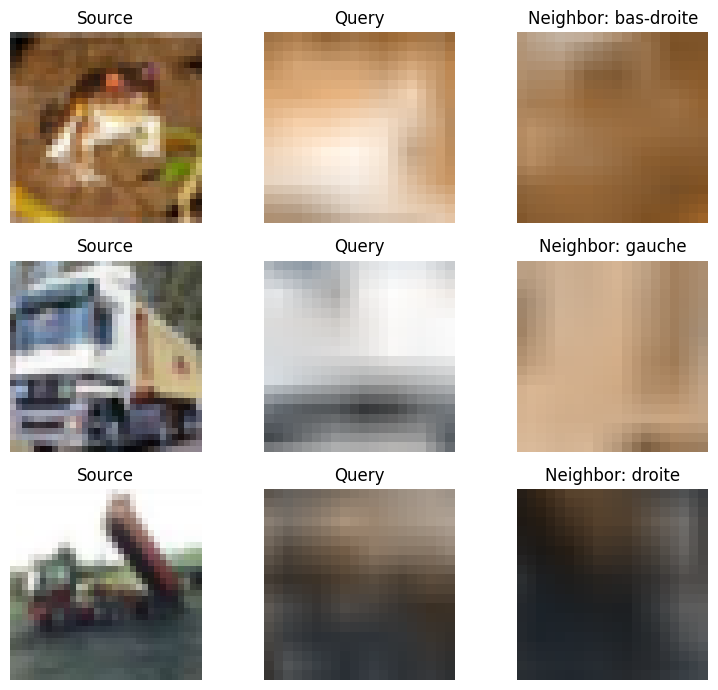

In [33]:
# Exemples de patches et de leurs positions relatives.
from torchvision import datasets
import matplotlib.pyplot as plt
torch.manual_seed(0)
raw = datasets.CIFAR10(str(WORK / 'data'), train=True, download=True)
pair_transform = PatchPairTransform()
fig, axes = plt.subplots(3, 3, figsize=(8, 7))
for row in range(3):
    image, _ = raw[row]
    q, p, label = pair_transform(image)
    for ax, value, title in zip(axes[row], [image, (q*.5+.5).permute(1,2,0).clamp(0,1),
                                               (p*.5+.5).permute(1,2,0).clamp(0,1)],
                               ['Source', 'Query', 'Neighbor: '+POSITION_NAMES[label.item()]]):
        ax.imshow(value); ax.set_title(title); ax.axis('off')
fig.tight_layout()
fig.savefig(RUN_DIR/'patch_examples.png', dpi=160)
plt.show()


### Fonctions communes d’entraînement et d’évaluation

In [34]:
# Modèles, augmentations et chargement des données ; labels masqués au préentraînement.
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def to_device(x, device):
    return [to_device(t, device) for t in x] if isinstance(x, (list, tuple)) else x.to(device)

def make_model(task, dataset):
    from deepul_helper.tasks import ContextEncoder, RotationPrediction, SimCLR
    classes = 10 if dataset == 'cifar10' else 100
    if task == 'relative_position':
        return RelativePosition(dataset, classes)

    model = {'context_encoder': ContextEncoder, 'rotation': RotationPrediction, 'simclr': SimCLR}[task]('cifar10', classes)
    return model

class TwoViews:
    def __init__(self, transform):
        self.transform = transform

    def __call__(self, image):
        return self.transform(image), self.transform(image)

class ColorProjection:
    def __call__(self, x):
        return project_color(x)

def transform_for(task, train=False):
    if task == 'context_encoder':

        mean, std = (.5,)*3, (.5,)*3
        return T.Compose([T.Resize(128), T.ToTensor(), T.Normalize(mean, std)])
    if task == 'relative_position':
        if train:
            return PatchPairTransform()
        return T.Compose([T.ToTensor(), ColorProjection(), T.Normalize((.5,)*3, (.5,)*3)])
    mean, std = (.4914,.4822,.4465), (.247,.243,.261)
    if task == 'simclr':
        std = (.2023,.1994,.2010)
        if train:
            return TwoViews(T.Compose([T.RandomResizedCrop(32, scale=(.2,1.)), T.RandomHorizontalFlip(),
                T.RandomApply([T.ColorJitter(.4,.4,.4,.1)], p=.8), T.RandomGrayscale(p=.2),
                T.ToTensor(), T.Normalize(mean, std)]))
    prefix = [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()] if train else []
    return T.Compose(prefix + [T.ToTensor(), T.Normalize(mean, std)])

class View(Dataset):
    def __init__(self, raw, indices, transform, unlabeled=False):
        self.raw, self.indices, self.transform, self.unlabeled = raw, list(indices), transform, unlabeled

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, label = self.raw[self.indices[i]]

        return self.transform(image), (-1 if self.unlabeled else label)

def loader(ds, batch, shuffle=False, workers=2, drop_last=False):
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=workers,
                      pin_memory=torch.cuda.is_available(), drop_last=drop_last)


In [35]:
# Préentraînement auto-supervisé ; checkpoint sauvegardé à chaque époque.
def atomic_save(value, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(value, tmp)
    os.replace(tmp, path)

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if torch.cuda.is_available() and state['cuda']:
        torch.cuda.set_rng_state_all([x.cpu() for x in state['cuda']])

def pretrain(model, train_loader, cfg, run_dir, device):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
    checkpoint = Path(run_dir) / 'pretrain.pt'
    start, history = 0, []
    if checkpoint.exists():

        state = torch.load(checkpoint, map_location='cpu', weights_only=False)
        model.load_state_dict(state['model'])
        opt.load_state_dict(state['optimizer'])
        start, history = state['epoch'], state['history']
        restore_rng(state['rng'])
        print(f'Resuming after epoch {start}', flush=True)
    for epoch in range(start, cfg['epochs']):
        model.train()
        sums, count = {}, 0
        begin = time.perf_counter()
        for inputs, _ in train_loader:
            inputs = to_device(inputs, device)
            n = len(inputs[0]) if isinstance(inputs, list) else len(inputs)
            opt.zero_grad(set_to_none=True)
            metrics, _ = model(inputs)
            if not torch.isfinite(metrics['Loss']):
                raise FloatingPointError('Non-finite pretext loss')
            metrics['Loss'].backward()
            opt.step()
            for key, value in metrics.items():
                sums[key] = sums.get(key, 0.) + float(value.detach())*n
            count += n
        if count == 0:
            raise ValueError('No training batches: increase sample count or lower batch size.')
        row = {'epoch': epoch+1, 'seconds': time.perf_counter()-begin, **{k:v/count for k,v in sums.items()}}
        history.append(row)
        print(row, flush=True)
        atomic_save(dict(model=model.state_dict(), optimizer=opt.state_dict(), epoch=epoch+1,
                         history=history, rng=rng_state()), checkpoint)
        Path(run_dir, 'history.json').write_text(json.dumps(history, indent=2))
    model.eval()
    return history


In [36]:
# Extraction sur disque, encodeur gelé et sélection sur la validation.
@torch.inference_mode()
def extract_features(model, data_loader, cache_path, device):

    print(f'Extraction : {Path(cache_path).name} ({len(data_loader.dataset)} images)', flush=True)
    model.eval()
    feature_path, label_path = Path(str(cache_path)+'.npy'), Path(str(cache_path)+'_labels.npy')
    feature_path.parent.mkdir(parents=True, exist_ok=True)
    features = None
    labels = np.empty(len(data_loader.dataset), dtype=np.int64)
    offset = 0
    for images, target in data_loader:
        z = model.encode(images.to(device)).flatten(1).float().cpu().numpy()
        if features is None:
            features = np.lib.format.open_memmap(feature_path, mode='w+', dtype=np.float32,
                                                 shape=(len(labels), z.shape[1]))
        features[offset:offset+len(z)] = z
        labels[offset:offset+len(z)] = target.numpy()
        offset += len(z)
    if offset != len(labels) or features is None:
        raise ValueError('Feature extraction did not cover the dataset.')
    features.flush()
    np.save(label_path, labels)
    return TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))

@torch.inference_mode()
def evaluate_probe(probe, feature_loader, device):
    probe.eval()
    correct1 = correct5 = total = 0
    for x, y in feature_loader:
        x, y = x.to(device), y.to(device)
        logits = probe(x)
        pred = logits.topk(min(5, logits.shape[1]), dim=1).indices
        correct1 += int((pred[:,0] == y).sum())
        correct5 += int((pred == y[:,None]).any(1).sum())
        total += len(y)
    return {'top1': 100*correct1/total, 'top5': 100*correct5/total, 'n': total}

def fit_probe(model, train_features, val_features, cfg, run_dir, device):

    model.eval().requires_grad_(False)
    probe = model.construct_classifier().to(device)
    opt = torch.optim.Adam(probe.parameters(), lr=1e-3, weight_decay=1e-4)
    train_loader = loader(train_features, cfg['probe_batch'], True, 0, True)
    val_loader = loader(val_features, cfg['probe_batch'], workers=0)
    best, best_state = -1., None
    history = []
    for epoch in range(cfg['probe_epochs']):
        probe.train()
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            F.cross_entropy(probe(x.to(device)), y.to(device)).backward()
            opt.step()
        val = evaluate_probe(probe, val_loader, device)
        history.append({'epoch': epoch+1, **val})
        print(f"Classifieur {epoch+1}/{cfg['probe_epochs']} — validation : {val['top1']:.2f}%", flush=True)
        if val['top1'] > best:
            best, best_state = val['top1'], copy.deepcopy(probe.state_dict())
    if best_state is None:
        raise ValueError('probe_epochs must be positive.')
    probe.load_state_dict(best_state)
    atomic_save({'probe': best_state, 'validation_top1': best, 'history': history}, Path(run_dir)/'probe.pt')
    return probe, best


In [37]:
# Entraîner une méthode, afficher son résultat et sauvegarder ses mesures.
def run_experiment(dataset, task):
    from sklearn.model_selection import train_test_split
    device = torch.device('cuda')
    seed_all(CFG['seed'])
    folder = RUN_DIR / f'{dataset}_{task}'
    folder.mkdir(exist_ok=True)
    cache = Path('/kaggle/temp/tp_ssl/features') / RUN_DIR.name / folder.name
    cls = datasets.CIFAR10 if dataset == 'cifar10' else datasets.CIFAR100
    train_data = cls(str(WORK / 'data'), train=True, download=True)
    test_data = cls(str(WORK / 'data'), train=False, download=True)
    train_idx, val_idx = train_test_split(np.arange(len(train_data)), test_size=0.1,
                                          stratify=train_data.targets, random_state=CFG['seed'])
    model = make_model(task, dataset)
    batch = CFG['context_batch'] if task == 'context_encoder' else CFG['batch_size']
    print(f'{dataset} | {task}', flush=True)
    unlabeled = View(train_data, train_idx, transform_for(task, train=True), unlabeled=True)
    history = pretrain(model, loader(unlabeled, batch, True, CFG['workers'], True), CFG, folder, device)
    features = []
    for name, indices in [('train', train_idx), ('validation', val_idx)]:
        data = View(train_data, indices, transform_for(task))
        features.append(extract_features(model, loader(data, batch, workers=CFG['workers']), cache / name, device))
    probe, validation = fit_probe(model, *features, CFG, folder, device)
    test_view = View(test_data, range(len(test_data)), transform_for(task))
    test_features = extract_features(model, loader(test_view, batch, workers=CFG['workers']), cache / 'test', device)
    scores = evaluate_probe(probe, loader(test_features, CFG['probe_batch'], workers=0), device)
    row = dict(dataset=dataset, task=task, validation_top1=validation,
               test_top1=scores['top1'], test_top5=scores['top5'],
               pretrain_seconds=sum(h['seconds'] for h in history))
    (folder / 'result.json').write_text(json.dumps(row, indent=2))
    results[:] = [r for r in results if (r['dataset'], r['task']) != (dataset, task)]
    results.append(row)
    pd.DataFrame(results).to_csv(RUN_DIR / 'comparison.csv', index=False)
    display(pd.DataFrame([row]))
    del model, probe, features, test_features
    gc.collect()
    torch.cuda.empty_cache()
    shutil.rmtree(cache)


### Consignes 4 et 6 — Les huit expériences
Chaque cellule entraîne une méthode, puis affiche ses scores de classification. Relancer la cellule des paramètres crée une nouvelle série d’entraînements.

In [38]:
# Entraîner et évaluer context_encoder sur CIFAR10.
run_experiment('cifar10', 'context_encoder')


cifar10 | context_encoder
{'epoch': 1, 'seconds': 289.189695607, 'Loss': 0.08857568785558809}
{'epoch': 2, 'seconds': 287.3003491559998, 'Loss': 0.060395986652518406}
{'epoch': 3, 'seconds': 287.29376268300075, 'Loss': 0.05546304313558688}
{'epoch': 4, 'seconds': 287.18012894299954, 'Loss': 0.05282134089783194}
{'epoch': 5, 'seconds': 287.171662021, 'Loss': 0.050791297637848225}
{'epoch': 6, 'seconds': 287.7670684469995, 'Loss': 0.04888855887160956}
{'epoch': 7, 'seconds': 288.1163239309999, 'Loss': 0.04720784317315218}
{'epoch': 8, 'seconds': 285.10340500000075, 'Loss': 0.045795368038616}
{'epoch': 9, 'seconds': 285.09494261300006, 'Loss': 0.044656684681783784}
{'epoch': 10, 'seconds': 283.56938795600036, 'Loss': 0.04340091984385193}
{'epoch': 11, 'seconds': 281.03227435699955, 'Loss': 0.04247527817001892}
{'epoch': 12, 'seconds': 279.0239751930003, 'Loss': 0.0415218560923299}
{'epoch': 13, 'seconds': 277.16269401999944, 'Loss': 0.04070551017667584}
{'epoch': 14, 'seconds': 277.598228

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar10,context_encoder,53.34,52.47,93.63,5630.926052


In [39]:
# Entraîner et évaluer rotation sur CIFAR10.
run_experiment('cifar10', 'rotation')


cifar10 | rotation
{'epoch': 1, 'seconds': 126.25544442899991, 'Loss': 0.8776590776579333, 'Acc1': 63.281806445868945}
{'epoch': 2, 'seconds': 123.94334317600078, 'Loss': 0.6634983210651962, 'Acc1': 73.81643963675214}
{'epoch': 3, 'seconds': 124.65395886899933, 'Loss': 0.5712781009341237, 'Acc1': 77.86959134615384}
{'epoch': 4, 'seconds': 124.9378810770013, 'Loss': 0.5092498750088901, 'Acc1': 80.46708066239316}
{'epoch': 5, 'seconds': 125.07464123199861, 'Loss': 0.4683994819805493, 'Acc1': 81.94778311965813}
{'epoch': 6, 'seconds': 124.45891778399891, 'Loss': 0.432057456922667, 'Acc1': 83.5876290954416}
{'epoch': 7, 'seconds': 124.42851817700102, 'Loss': 0.40292306155221075, 'Acc1': 84.7389155982906}
{'epoch': 8, 'seconds': 125.42291345400008, 'Loss': 0.38099136969812236, 'Acc1': 85.61253561253561}
{'epoch': 9, 'seconds': 125.43313903499984, 'Loss': 0.3604686234751318, 'Acc1': 86.40602742165242}
{'epoch': 10, 'seconds': 124.62141922699993, 'Loss': 0.34006922528614686, 'Acc1': 87.237913

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar10,rotation,76.16,75.75,98.31,2494.86422


In [40]:
# Entraîner et évaluer simclr sur CIFAR10.
run_experiment('cifar10', 'simclr')


cifar10 | simclr
{'epoch': 1, 'seconds': 367.0685996379998, 'Loss': 9.259350170776715}
{'epoch': 2, 'seconds': 366.1739366740003, 'Loss': 8.721057736975515}
{'epoch': 3, 'seconds': 364.9864921119988, 'Loss': 8.524826628530127}
{'epoch': 4, 'seconds': 366.169180384999, 'Loss': 8.393834940049043}
{'epoch': 5, 'seconds': 365.31552826499865, 'Loss': 8.29806027860723}
{'epoch': 6, 'seconds': 366.54752101600025, 'Loss': 8.236049986293173}
{'epoch': 7, 'seconds': 365.3746823800011, 'Loss': 8.182610973673329}
{'epoch': 8, 'seconds': 365.1673240809996, 'Loss': 8.131327243272395}
{'epoch': 9, 'seconds': 365.07759189199896, 'Loss': 8.098956897387817}
{'epoch': 10, 'seconds': 366.0142666610009, 'Loss': 8.067020480109756}
{'epoch': 11, 'seconds': 366.38761371500004, 'Loss': 8.044062937766398}
{'epoch': 12, 'seconds': 365.28257822199885, 'Loss': 8.019234704835462}
{'epoch': 13, 'seconds': 366.2216179019997, 'Loss': 8.008354680151003}
{'epoch': 14, 'seconds': 365.5624220460013, 'Loss': 7.984917454570

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar10,simclr,75.62,75.82,98.77,7315.009317


In [41]:
# Entraîner et évaluer relative_position sur CIFAR10.
run_experiment('cifar10', 'relative_position')


cifar10 | relative_position
{'epoch': 1, 'seconds': 24.030532633001712, 'Loss': 1.9933261008683774, 'Acc1': 20.096599002849004}
{'epoch': 2, 'seconds': 22.603872576000867, 'Loss': 1.883471760654721, 'Acc1': 26.406695156695157}
{'epoch': 3, 'seconds': 21.571366408999893, 'Loss': 1.798183515540555, 'Acc1': 30.377492877492877}
{'epoch': 4, 'seconds': 21.694629312998586, 'Loss': 1.7611101026888247, 'Acc1': 32.10470085470085}
{'epoch': 5, 'seconds': 21.919026988998667, 'Loss': 1.735591946504055, 'Acc1': 33.06178774928775}
{'epoch': 6, 'seconds': 21.712385539001843, 'Loss': 1.7128550758388987, 'Acc1': 34.64877136752137}
{'epoch': 7, 'seconds': 21.656718005000585, 'Loss': 1.6990398847819055, 'Acc1': 35.17628205128205}
{'epoch': 8, 'seconds': 21.56352282199805, 'Loss': 1.6784737266366638, 'Acc1': 35.79950142450142}
{'epoch': 9, 'seconds': 21.685498743001517, 'Loss': 1.6670150947027396, 'Acc1': 36.64752492877493}
{'epoch': 10, 'seconds': 21.81406388799951, 'Loss': 1.6503660841884775, 'Acc1': 37

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar10,relative_position,61.42,61.88,95.86,438.272117


In [42]:
# Entraîner et évaluer context_encoder sur CIFAR100.
run_experiment('cifar100', 'context_encoder')


100%|██████████| 169M/169M [20:39<00:00, 136kB/s]  


cifar100 | context_encoder
{'epoch': 1, 'seconds': 286.60337860800064, 'Loss': 0.08763400696027245}
{'epoch': 2, 'seconds': 285.7770556819996, 'Loss': 0.05787099388084913}
{'epoch': 3, 'seconds': 286.00906961200235, 'Loss': 0.051662625350153465}
{'epoch': 4, 'seconds': 285.035119174001, 'Loss': 0.04875782676634629}
{'epoch': 5, 'seconds': 285.7659765089993, 'Loss': 0.04663953611131752}
{'epoch': 6, 'seconds': 286.0945044879991, 'Loss': 0.044748847213855934}
{'epoch': 7, 'seconds': 286.8078041410008, 'Loss': 0.04316569311917888}
{'epoch': 8, 'seconds': 285.4968259030029, 'Loss': 0.042041379563605805}
{'epoch': 9, 'seconds': 282.80441878400234, 'Loss': 0.040941769817571125}
{'epoch': 10, 'seconds': 281.3283171949988, 'Loss': 0.039937678913971354}
{'epoch': 11, 'seconds': 278.92416987400065, 'Loss': 0.03938576478277933}
{'epoch': 12, 'seconds': 276.6179745990012, 'Loss': 0.03834310943422412}
{'epoch': 13, 'seconds': 276.49036711900044, 'Loss': 0.03777324702924549}
{'epoch': 14, 'seconds':

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar100,context_encoder,22.96,22.77,48.41,5599.431841


In [43]:
# Entraîner et évaluer rotation sur CIFAR100.
run_experiment('cifar100', 'rotation')


cifar100 | rotation
{'epoch': 1, 'seconds': 125.85415448799904, 'Loss': 1.1310086131435513, 'Acc1': 50.26876335470085}
{'epoch': 2, 'seconds': 123.52852185899974, 'Loss': 1.004314492231081, 'Acc1': 57.65446937321937}
{'epoch': 3, 'seconds': 124.66207951099932, 'Loss': 0.9386541269443653, 'Acc1': 60.96031428062678}
{'epoch': 4, 'seconds': 124.39513751600316, 'Loss': 0.8886919386706121, 'Acc1': 63.402555199430196}
{'epoch': 5, 'seconds': 123.98242946400205, 'Loss': 0.8453998623410521, 'Acc1': 65.45584045584046}
{'epoch': 6, 'seconds': 124.03969730099925, 'Loss': 0.8128108134296884, 'Acc1': 67.04226762820512}
{'epoch': 7, 'seconds': 124.90167726599975, 'Loss': 0.7786887439227851, 'Acc1': 68.64983974358974}
{'epoch': 8, 'seconds': 125.124406687999, 'Loss': 0.7538850105386175, 'Acc1': 69.61916844729345}
{'epoch': 9, 'seconds': 124.82906751799965, 'Loss': 0.7280175203611369, 'Acc1': 70.89676816239316}
{'epoch': 10, 'seconds': 123.62114859199937, 'Loss': 0.7024775841976503, 'Acc1': 72.0413773

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar100,rotation,48.9,48.84,75.99,2488.653182


In [44]:
# Entraîner et évaluer simclr sur CIFAR100.
run_experiment('cifar100', 'simclr')


cifar100 | simclr
{'epoch': 1, 'seconds': 365.1314228980009, 'Loss': 9.214965094867935}
{'epoch': 2, 'seconds': 366.21307163000165, 'Loss': 8.72242243405421}
{'epoch': 3, 'seconds': 364.3500953620023, 'Loss': 8.548796180985931}
{'epoch': 4, 'seconds': 365.91685858300116, 'Loss': 8.428213013543022}
{'epoch': 5, 'seconds': 366.895929721999, 'Loss': 8.325491340072066}
{'epoch': 6, 'seconds': 364.42540603700036, 'Loss': 8.26445471391379}
{'epoch': 7, 'seconds': 365.6356940000005, 'Loss': 8.211066254183777}
{'epoch': 8, 'seconds': 365.71628441400026, 'Loss': 8.170613623072958}
{'epoch': 9, 'seconds': 365.9696881580021, 'Loss': 8.139440775596858}
{'epoch': 10, 'seconds': 366.4340604479985, 'Loss': 8.114287012323015}
{'epoch': 11, 'seconds': 365.9810778120009, 'Loss': 8.102599975390312}
{'epoch': 12, 'seconds': 366.88642461400013, 'Loss': 8.07941118196884}
{'epoch': 13, 'seconds': 366.7800810099943, 'Loss': 8.06647539274645}
{'epoch': 14, 'seconds': 367.0379112149967, 'Loss': 8.04947333458142

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar100,simclr,41.1,41.13,70.84,7321.525225


In [45]:
# Entraîner et évaluer relative_position sur CIFAR100.
run_experiment('cifar100', 'relative_position')


cifar100 | relative_position
{'epoch': 1, 'seconds': 24.103977152997686, 'Loss': 1.9886440914920254, 'Acc1': 20.23682336182336}
{'epoch': 2, 'seconds': 22.49387325099815, 'Loss': 1.8776353431223465, 'Acc1': 26.67156339031339}
{'epoch': 3, 'seconds': 21.556497300996853, 'Loss': 1.8098520437876384, 'Acc1': 30.2261396011396}
{'epoch': 4, 'seconds': 21.58427976800158, 'Loss': 1.7610541072666135, 'Acc1': 32.7190170940171}
{'epoch': 5, 'seconds': 23.076887853996595, 'Loss': 1.7375363383198057, 'Acc1': 33.34891381766382}
{'epoch': 6, 'seconds': 22.011061990997405, 'Loss': 1.7154982738685065, 'Acc1': 34.644319800569804}
{'epoch': 7, 'seconds': 21.614088724003523, 'Loss': 1.6877395790866299, 'Acc1': 35.96643518518518}
{'epoch': 8, 'seconds': 21.579333891000715, 'Loss': 1.668175936764122, 'Acc1': 37.16613247863248}
{'epoch': 9, 'seconds': 21.837291157004074, 'Loss': 1.6509516259543917, 'Acc1': 37.76264245014245}
{'epoch': 10, 'seconds': 21.606502233000356, 'Loss': 1.6277258936156573, 'Acc1': 38.

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar100,relative_position,31.1,32.31,59.63,437.701214


### Consigne 6 — Résultats

,dataset,task,validation_top1,test_top1,test_top5,pretrain_seconds
0,cifar10,context_encoder,53.34,52.47,93.63,5630.926052
3,cifar10,relative_position,61.42,61.88,95.86,438.272117
1,cifar10,rotation,76.16,75.75,98.31,2494.864220
2,cifar10,simclr,75.62,75.82,98.77,7315.009317
4,cifar100,context_encoder,22.96,22.77,48.41,5599.431841
7,cifar100,relative_position,31.10,32.31,59.63,437.701214
5,cifar100,rotation,48.90,48.84,75.99,2488.653182
6,cifar100,simclr,41.10,41.13,70.84,7321.525225


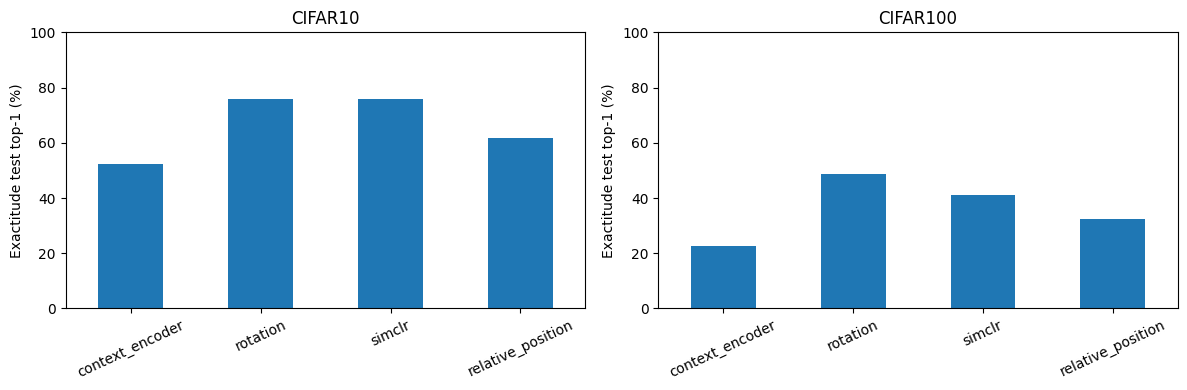

In [46]:
# Tableau et graphique comparant les huit entraînements.
comparison = pd.DataFrame(results).sort_values(['dataset', 'task'])
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    values = comparison[comparison.dataset == dataset].set_index('task').reindex(TASKS)
    values.test_top1.plot.bar(ax=ax, rot=25)
    ax.set(title=dataset.upper(), ylabel='Exactitude test top-1 (%)', ylim=(0, 100), xlabel='')
fig.tight_layout()
fig.savefig(RUN_DIR / 'comparison.png', dpi=160)
plt.show()


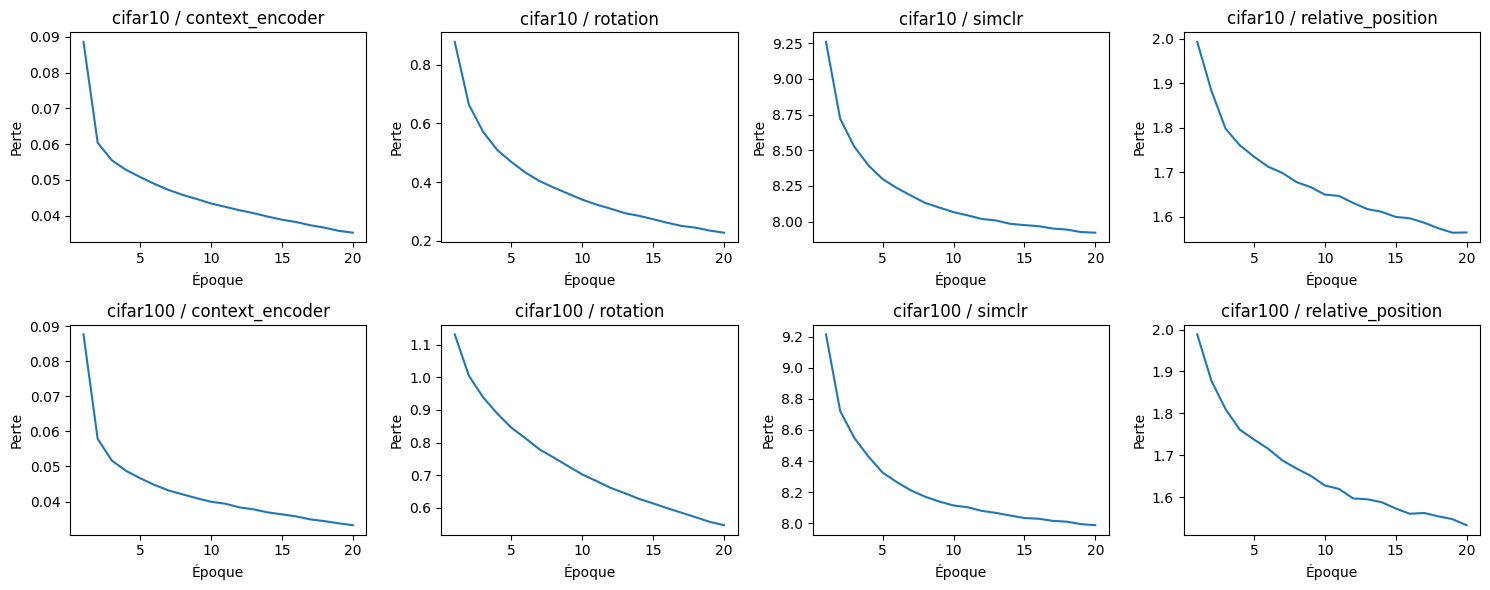

In [47]:
# Courbes de perte des tâches auto-supervisées.
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, dataset in enumerate(DATASETS):
    for j, task in enumerate(TASKS):
        history = pd.read_json(RUN_DIR / f'{dataset}_{task}' / 'history.json')
        axes[i, j].plot(history.epoch, history.Loss)
        axes[i, j].set(title=f'{dataset} / {task}', xlabel='Époque', ylabel='Perte')
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160)
plt.show()


Sources : [notebook fourni](https://github.com/ckurtz/teaching_UPC_UFRMI/blob/main/selfsupervised_demos.ipynb), [bibliothèque](https://github.com/ckurtz/cs294-158-ssl), [Context Encoder](https://arxiv.org/abs/1604.07379), [Rotation](https://arxiv.org/abs/1803.07728), [SimCLR](https://arxiv.org/abs/2002.05709), [Position relative](https://arxiv.org/abs/1505.05192).